# Práctica 5 - Visión por Computador
## Marcial Galván - Alejandra Rodríguez

En este cuaderno se juntan todos los análisis llevados a cabo para realizar 2 tareas de detección y caracterización de rasgos faciales. Las tareas realizadas son:
- **Tarea A**: detección de estado de ánimo en una lectura en voz alta.
- **Tarea B**: filtro inspirado en _Ceci n'est pas une pipe_.

## 1. Configuración

In [ ]:
import time

import cv2
import matplotlib.pyplot as plt
import sounddevice as sd
from matplotlib.patches import Ellipse

from common.experiment import ASSETS, PIPE_RESULTS, READING_RESULTS
from common.faces.detectors import DETECTORS, largest_face
from common.pipe.landmarks import Hands, MouthOpening, draw_landmarks
from common.pipe.pipe import load_sprite
from common.pipe.scene import PipeScene
from common.reading.drowsiness import STEP_S
from common.reading.report import plot_report
from common.reading.session import SAMPLE_RATE, ReadingSession

PIPE_RESULTS.mkdir(parents=True, exist_ok=True)
READING_RESULTS.mkdir(parents=True, exist_ok=True)

## 2. Tarea A: Estado de ánimo durante una lectura

La detección del estado de ánimo es un problema con aplicabilidad en un gran número de áreas. Por ejemplo, esta tarea busca entender si una persona mantiene la atención o se está quedando dormida, y cómo reacciona a lo que oye.

Esta herramienta podría ser utilizada, por ejemplo, por profesores o ponentes para saber en qué momentos pierden la atención de su público.

Concretamente, en la tarea implementada se reproduce el capítulo 1 del **Quijote**, mientras se analiza en directo quien lo está escuchando. Se analizan 2 elementos:

- **Somnolencia**: alerta, poca atención o somnolencia.
- **Emoción**: emoción predominante en la cara.

Al terminar, se muestra mediante gráficas la evolución de estos elementos durante la lectura. Para la detección de cada uno de ellos, se han estudiado distintas alternativas, con el fin de utilizar las que proporcionaran mejores resultados. Concretamente, los modelos usados son:

- **Somnolencia**: Random Forest calibrado, entrenado con UTA-RLDD ([drowsiness_training.ipynb](drowsiness_detection/drowsiness_training.ipynb)).
- **Emociones**: ResNet-18 entrenada con FER+ ([emotion_training.ipynb](emotion_detection/emotion_training.ipynb)).


### 2.1. Funcionamiento

La lectura se encuentra pregrabada en [`assets/lectura.mp3`](assets/lectura.mp3) junto con un CSV en el que se registran sus frases ([`assets/lectura.csv`](assets/lectura.csv)), para poder seguir la lectura mientras se realiza la demostración. Mientras suena, se siguen las siguientes etapas:

- **Calibración** (primeros 40 s; en el entrenamiento se usó un minuto, pero se acorta para que la demostración empiece antes): para ajustar los cálculos del _Eye Aspect Ratio_, se mide la apertura de los ojos y la postura de la cabeza de la persona.
- **Somnolencia**: cada 10 s se mide el estado de cansancio. Se combinan distintos tamaños de ventana para realizar una demostración rápida y robusta.
- **Emociones**: se detecta la emoción de la persona 5 veces por segundo y se muestra la dominante en pantalla.

La implementación se encuentra en [`common/reading/`](common/reading):

- **Somnolencia** (`Drowsiness`, [`drowsiness.py`](common/reading/drowsiness.py)): guarda los rasgos de cada fotograma (EAR, MAR, postura...).
- **Emociones** (`Emotions`, [`emotions.py`](common/reading/emotions.py)): recorta la cara a 48 × 48 en escala de grises (como en FER2013) y la clasifica con la ResNet-18.
- **Texto** ([`overlay.py`](common/reading/overlay.py)): escribe texto (frase de la lectura y emoción actual) sobre la ventana.
- **Sesión** (`ReadingSession`, [`session.py`](common/reading/session.py)): carga la lectura y une las piezas anteriores.
- **Informe** (`plot_report`, [`report.py`](common/reading/report.py)): realiza un informe del estado de ánimo del participante durante toda la lectura, generando curvas de somnolencia y mostrando la emoción predominante cada 10 s.

### 2.2. Prototipo con la webcam

Durante la demostración, se guardan las características detectadas en cada fotograma para ser procesadas en el informe. La demostración solo se ejecuta si `RUN_READING = True`.

Controles:

| Tecla | Acción |
|---|---|
| **Q** o **ESC** | Terminar la lectura |

Si se termina la lectura, se conserva todo el análisis realizado hasta ese momento, almacenándolo en `session`.

In [ ]:
RUN_READING = True


def run_reading(session, camera=0):
    capture = cv2.VideoCapture(camera)
    sd.play(session.audio, SAMPLE_RATE)
    start = time.perf_counter()
    try:
        while (t := time.perf_counter() - start) < session.duration:
            ok, frame = capture.read()
            if not ok:
                break
            session.update(frame, t)
            cv2.imshow("Lectura", session.draw(frame, t))
            if cv2.waitKey(1) & 0xFF in (27, ord("q")):
                break
    finally:
        sd.stop()
        capture.release()
        cv2.destroyAllWindows()


if RUN_READING:
    session = ReadingSession(ASSETS / "lectura.mp3", ASSETS / "lectura.csv")
    run_reading(session)

### 2.3. Informe

Arriba, la probabilidad de cada estado, en el instante en que se calculó. Abajo, la emoción que predomina en cada tramo de 10 s (_neutral_ incluida), con su altura según la fracción de caras clasificadas con ella. El informe se guarda en `results/reading/`.

In [ ]:
if RUN_READING:
    report = plot_report(session.drowsiness.table(), session.emotions.table(STEP_S), session.elapsed)
    report.savefig(READING_RESULTS / f"lectura_{time.strftime('%Y%m%d_%H%M%S')}.png", dpi=120)
    plt.show()

## 3. Tarea B: Filtro - _Ceci n'est pas une pipe_

La inspiración para esta segunda tarea es la composición _La trahison des images_ (1929), en la que Magritte pinta la _representación_ de una pipa. En esta tarea, se realiza un filtro en el que se puede fumar la pipa de Magritte:

- La pipa flota en la imagen. Se puede coger pinzándola y moverla hacia donde se desee. Mientras se sujeta, la boquilla apunta a la boca.
- Al llevar la boquilla a la boca, se inhala y la cazoleta se enciende. Los pulmones se llenan paulatinamente.
- El humo sale siempre que se abre la boca. Al cerrarla, el humo restante se mantiene en los pulmones, hasta que se vuelve a abrir.

En este filtro, se necesita detección de caras, de manos y de _landmarks_. Para el detector facial, se utiliza YuNet, tras estudiar sus resultados en la [comparativa](face_detectors.ipynb#7-conclusiones):

In [27]:
face_detector = DETECTORS["yunet"]()
face_detector.threshold = 0.77

Para los detectores de manos y _landmarks_, se ha decidido utilizar los incluidos en MediaPipe (`HandLandmarker` y `FaceLandmarker`), por su buen _trade-off_ entre resultados y tiempo de ejecución (incluso en CPU).

### 3.1. Funcionamiento

La pipa es una imagen PNG con transparencia, recortada sobre la imagen original ([`assets/pipe.png`](assets/pipe.png)). Sobre esta imagen, también se han determinado puntos característicos (boquilla, cazoleta), en [`assets/pipe.json`](assets/pipe.json). Si se quisiera utilizar otra imagen, basta con cambiar estos dos ficheros.

Estos son los puntos característicos detectados sobre la imagen utilizada:

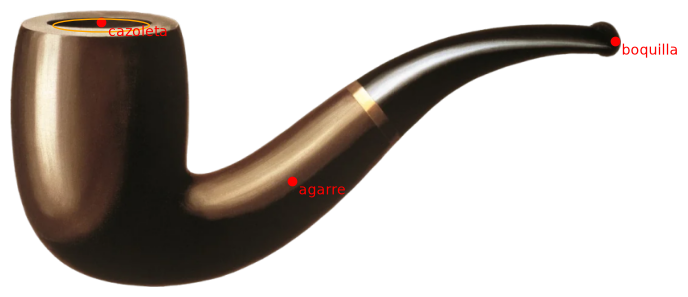

In [30]:
sprite = load_sprite(ASSETS / "pipe.png")

plt.figure(figsize=(8, 3.6))
plt.imshow(cv2.cvtColor(sprite["image"], cv2.COLOR_BGRA2RGBA))
for name, point in {"agarre": sprite["grip"], "boquilla": sprite["tip"], "cazoleta": sprite["bowl"]}.items():
    plt.scatter(*point, color="red")
    plt.annotate(name, point, xytext=(5, -10), textcoords="offset points", color="red")
plt.gca().add_patch(Ellipse(sprite["ember"][:2], *2 * sprite["ember"][2:], fill=False, color="orange"))
plt.axis("off")
plt.show()

La implementación de las distintas partes del filtro se encuentra en [`common/pipe/`](common/pipe).:

- **Pipa** (`Pipe`, [`pipe.py`](common/pipe/pipe.py)): se coloca sobre la escena con transformaciones. Su largo se ajusta al tamaño de la cara, se gira para apuntar la boquilla a la boca al cogerla y se endereza al soltarla. También dibuja la brasa, (elipse naranja en la cazoleta).
- **Mano** (`Hands`, [`landmarks.py`](common/pipe/landmarks.py), y `PinchGrab`, [`scene.py`](common/pipe/scene.py)): MediaPipe devuelve 21 _landmarks_ por mano. Se detecta el agarre utilizando la distancia entre las puntas del pulgar y del índice, dividida entre el tamaño de la mano.
- **Boca** (`MouthOpening`, [`landmarks.py`](common/pipe/landmarks.py)): se utiliza el `FaceLandmarker` de MediaPipe sobre el recorte de la cara realizado por YuNet, para conocer la apertura de la boca.
- **Humo** (`Smoke`, [`smoke.py`](common/pipe/smoke.py)): sistema de partículas. Se crean en la cazoleta o en la boca. Se dibujan como manchas gaussianas que crecen y se aclaran con la edad. Como es habitual en este tipo de sistemas, la opacidad es $1 - e^{-\text{densidad}}$, lo que causa el espesor del humo donde se acumula.
- **Escena** (`PipeScene`, [`scene.py`](common/pipe/scene.py), y `Smoking`, [`smoking.py`](common/pipe/smoking.py)): une las distintas piezas para generar el _pipeline_ ya mencionado.

### 3.2 Prototipo con la webcam

La imagen se muestra en modo espejo, para facilitar la interacción con la demostración. Esta solo se ejecuta si `RUN_PIPE = True`. 

Estos son los controles disponibles por teclado (además de la interacción con el cuerpo ya mencionada):

| Tecla | Acción |
|---|---|
| **R** | Devolver la pipa a su sitio |
| **L** | Mostrar u ocultar los puntos que detectan los modelos |
| **V** | Empezar o parar la grabación, que se guarda en `results/pipe/` |
| **ESC** | Salir |

In [29]:
RUN_PIPE = True


def start_recording(frame):
    path = PIPE_RESULTS / f"pipe_{time.strftime('%Y%m%d_%H%M%S')}.mp4"
    print("Grabando en", path)
    return cv2.VideoWriter(str(path), cv2.VideoWriter_fourcc(*"mp4v"), 30, frame.shape[1::-1])


def run_pipe(camera=0):
    hands, mouth_opening = Hands(), MouthOpening()
    capture = cv2.VideoCapture(camera)
    scene, writer, show_landmarks = None, None, False
    previous = time.perf_counter()
    while True:
        ok, frame = capture.read()
        if not ok:
            break
        frame = cv2.flip(frame, 1)
        now = time.perf_counter()
        dt, previous = min(now - previous, 0.1), now
        scene = scene or PipeScene(sprite, frame.shape)

        face = largest_face(face_detector(frame))
        openness = mouth_opening(frame, face) if face is not None else None
        hand_points = hands(frame)
        scene.update(face, openness, hand_points, dt)
        scene.draw(frame)
        if show_landmarks:
            draw_landmarks(frame, face, hand_points, mouth_opening.lips)

        if writer is not None:
            writer.write(frame)
            cv2.circle(frame, (frame.shape[1] - 20, 20), 8, (0, 0, 255), -1)
        cv2.imshow("Ceci n'est pas une pipe", frame)

        key = cv2.waitKey(1) & 0xFF
        if key == 27:
            break
        elif key == ord("r"):
            scene.reset()
        elif key == ord("l"):
            show_landmarks = not show_landmarks
        elif key == ord("v"):
            writer = start_recording(frame) if writer is None else writer.release()
    if writer is not None:
        writer.release()
    capture.release()
    cv2.destroyAllWindows()


if RUN_PIPE:
    run_pipe()